# Lossless in-domain, lossy under shift? A CPU pilot of configuration-drift evaluation

**Ashhar Hussain** · companion to the research proposal *Lossless on the Benchmark, Lossy in Deployment? Reliability of LLM-Based Code Tools under Configuration Drift and Distribution Shift*

This notebook runs the proposal's evaluation protocol on a problem small enough for any CPU, with no downloads: scikit-learn's built-in handwritten-digits dataset (1,797 images of 8×8 pixels). It trains 10 small neural networks with different random seeds. Then, keeping each trained model fixed, it changes **only the inference configuration** and tests every configuration on the clean test images and on four shifted versions of them.

| Configuration | What changes |
|---|---|
| FP64 | reference: scikit-learn's own double precision |
| FP32, FP16 | lower floating-point precision |
| W8 | 8-bit weights (symmetric, per output channel) |
| W8A8 | 8-bit weights and 8-bit activations, with activation ranges calibrated on the training data (standard post-training quantization) |
| W4 | 4-bit weights |

**Question.** Does a configuration change that is harmless on in-distribution data stay harmless under distribution shift? The proposal asks the same question of LLM-based code tools at full scale. This pilot checks that the protocol works end to end: paired comparisons per test image, a measured noise floor, exact tests with Holm correction, bootstrap intervals, and a configuration × shift interaction.

Seeds, shifts, configurations, tests and the decision rule are all fixed before the run. Run time is about one minute on a CPU.

In [1]:
import os, time, json, platform, warnings
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.stats import binom
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 170)

SEEDS = list(range(10))       # training seeds
HIDDEN = (64,)                # one hidden layer of 64 ReLU units
ALPHA = 0.05                  # family-wise error rate
B = 10000                     # bootstrap resamples
CONFIGS = ["FP64", "FP32", "FP16", "W8", "W8A8", "W4"]
OUT = "config_drift_results"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
ENV = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
       "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__}
print(ENV)

{'python': '3.13.18', 'numpy': '2.5.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'pandas': '3.0.5', 'matplotlib': '3.11.2'}


In [2]:
X, y = load_digits(return_X_y=True)
X = X / 16.0                                   # pixel intensities in [0, 1]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, stratify=y, random_state=0)
rng = np.random.default_rng(2027)

def translate(Z, dx=1):
    imgs = Z.reshape(-1, 8, 8)
    out = np.zeros_like(imgs)
    out[:, :, dx:] = imgs[:, :, :-dx]          # one pixel to the right, zero fill
    return out.reshape(len(Z), -1)

CONDITIONS = {
    "clean": Xte,
    "pixel noise": np.clip(Xte + rng.normal(0, 0.15, Xte.shape), 0, 1),
    "low contrast": Xte * 0.5,
    "bright background": np.clip(Xte + 0.2, 0, 1),
    "1-pixel shift": translate(Xte),
}
n = len(yte)
print(f"training images: {len(Xtr)} | test images: {n} | test conditions: {list(CONDITIONS)}")

training images: 898 | test images: 899 | test conditions: ['clean', 'pixel noise', 'low contrast', 'bright background', '1-pixel shift']


In [3]:
def quant_weights(W, bits):
    # symmetric per-output-channel quantization, converted back to float (simulated integer inference)
    qmax = 2 ** (bits - 1) - 1
    s = np.abs(W).max(axis=0, keepdims=True) / qmax
    s[s == 0] = 1.0
    return np.clip(np.round(W / s), -qmax, qmax) * s

def act_ranges(Ws, bs, Xcal):
    # largest input value each layer sees on the calibration (training) data
    r, h = [], Xcal
    for i, (W, b) in enumerate(zip(Ws, bs)):
        r.append(float(h.max()))
        h = h @ W + b
        if i < len(Ws) - 1:
            h = np.maximum(h, 0)
    return r

def quant_act(h, hi, bits=8):
    # unsigned 8-bit activations (pixels and ReLU outputs are non-negative); values above the calibrated range are clipped
    qmax = 2 ** bits - 1
    return np.clip(np.round(h / (hi / qmax)), 0, qmax) * (hi / qmax)

def predict(Ws, bs, Z, cfg, ranges=None):
    dtype = {"FP32": np.float32, "FP16": np.float16}.get(cfg, np.float64)
    wbits = {"W8": 8, "W8A8": 8, "W4": 4}.get(cfg)
    h = Z.astype(dtype)
    for i, (W, b) in enumerate(zip(Ws, bs)):
        if cfg == "W8A8":
            h = quant_act(h, ranges[i])
        Wc = quant_weights(W, wbits) if wbits else W
        h = h @ Wc.astype(dtype) + b.astype(dtype)
        if i < len(Ws) - 1:
            h = np.maximum(h, 0)
    return np.asarray(h, dtype=np.float64).argmax(axis=1)

In [4]:
P = {}                                          # (seed, config, condition) -> predicted labels
agreement = []
for seed in SEEDS:
    clf = MLPClassifier(hidden_layer_sizes=HIDDEN, max_iter=500, random_state=seed).fit(Xtr, ytr)
    Ws, bs = clf.coefs_, clf.intercepts_
    ranges = act_ranges(Ws, bs, Xtr)
    agreement.append(float((predict(Ws, bs, Xte, "FP64") == clf.predict(Xte)).mean()))
    for cfg in CONFIGS:
        for cond, Z in CONDITIONS.items():
            P[(seed, cfg, cond)] = predict(Ws, bs, Z, cfg, ranges)
assert min(agreement) >= 0.999, "the reference forward pass must reproduce scikit-learn's predictions"
R = {k: (v == yte) for k, v in P.items()}       # correct / incorrect per test image

# noise floor: repeating a run with the same configuration
repeat = sum(int((predict(Ws, bs, Z, "FP64") != P[(SEEDS[-1], "FP64", c)]).sum()) for c, Z in CONDITIONS.items())
# for scale: retraining the same network with another seed
pairs = [(a, b) for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]]
SEED_FLIPS = {c: round(float(np.mean([(P[(a, "FP64", c)] != P[(b, "FP64", c)]).sum() for a, b in pairs])), 1) for c in CONDITIONS}
print(f"{len(SEEDS)} models trained and evaluated in {time.time() - T0:.1f} s")
print(f"reference forward pass matches scikit-learn on {100 * min(agreement):.1f}% of test images")
print(f"repeated runs with the same configuration: {repeat} changed predictions "
      "(inference is deterministic, so every flip below is caused by the configuration)")
print("for scale, retraining with another seed changes this many predictions on average:", SEED_FLIPS)

10 models trained and evaluated in 9.9 s
reference forward pass matches scikit-learn on 100.0% of test images
repeated runs with the same configuration: 0 changed predictions (inference is deterministic, so every flip below is caused by the configuration)
for scale, retraining with another seed changes this many predictions on average: {'clean': 15.7, 'pixel noise': 26.6, 'low contrast': 20.0, 'bright background': 45.3, '1-pixel shift': 154.8}


In [5]:
def sign_test(worse, better):
    # exact McNemar-type test on paired per-image differences
    m = worse + better
    return 1.0 if m == 0 else float(min(1.0, 2 * binom.cdf(min(worse, better), m, 0.5)))

def holm(p):
    p = np.asarray(p, float); adj = np.empty_like(p); run = 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(1.0, run)
    return adj

IDX = np.random.default_rng(0).integers(0, n, (B, n))     # bootstrap resamples of test images
def boot_ci(v, alpha=ALPHA):
    return np.percentile(v[IDX].mean(axis=1), [100 * alpha / 2, 100 * (1 - alpha / 2)])

# unit of analysis = test image; its correctness is averaged over the 10 trained models
MC = {(cfg, c): np.mean([R[(s, cfg, c)] for s in SEEDS], axis=0) for cfg in CONFIGS for c in CONDITIONS}

ACC = pd.DataFrame([{"config": cfg, "condition": c, "accuracy_%": 100 * MC[(cfg, c)].mean(),
                     "min_model_%": 100 * min(R[(s, cfg, c)].mean() for s in SEEDS),
                     "max_model_%": 100 * max(R[(s, cfg, c)].mean() for s in SEEDS)}
                    for cfg in CONFIGS for c in CONDITIONS])

rows = []
for cfg in CONFIGS[1:]:
    for c in CONDITIONS:
        d = MC[(cfg, c)] - MC[("FP64", c)]
        lo, hi = boot_ci(d)
        rows.append({"config": cfg, "condition": c,
                     "changed_per_model": float(np.mean([(P[(s, cfg, c)] != P[(s, "FP64", c)]).sum() for s in SEEDS])),
                     "delta_pp": 100 * d.mean(), "ci_lo_pp": 100 * lo, "ci_hi_pp": 100 * hi,
                     "images_worse": int((d < 0).sum()), "images_better": int((d > 0).sum()),
                     "p": sign_test(int((d < 0).sum()), int((d > 0).sum()))})
EFF = pd.DataFrame(rows)
EFF["p_holm"] = holm(EFF["p"])
EFF["significant_harm"] = (EFF["p_holm"] < ALPHA) & (EFF["delta_pp"] < 0)

shifts = [c for c in CONDITIONS if c != "clean"]
m_int = len(CONFIGS[1:]) * len(shifts)
rows = []
for cfg in CONFIGS[1:]:
    d0 = MC[(cfg, "clean")] - MC[("FP64", "clean")]
    for c in shifts:
        d1 = MC[(cfg, c)] - MC[("FP64", c)]
        lo, hi = boot_ci(d1 - d0, ALPHA / m_int)                 # Bonferroni-adjusted 95% intervals
        rows.append({"config": cfg, "shift": c, "effect_clean_pp": 100 * d0.mean(), "effect_shifted_pp": 100 * d1.mean(),
                     "interaction_pp": 100 * (d1 - d0).mean(), "ci_lo_pp": 100 * lo, "ci_hi_pp": 100 * hi,
                     "shift_makes_it_worse": bool(hi < 0)})
INT = pd.DataFrame(rows)

print("ACCURACY (%; mean of 10 models)")
display(ACC.pivot(index="config", columns="condition", values="accuracy_%").loc[CONFIGS, list(CONDITIONS)].round(2))
print("CONFIGURATION EFFECTS vs FP64 (pp = percentage points; harm claimed only if Holm-adjusted p < 0.05)")
display(EFF.round(4))
print("CONFIGURATION x SHIFT INTERACTION (effect under shift minus effect on clean data)")
display(INT.round(3))

ACCURACY (%; mean of 10 models)


condition,clean,pixel noise,low contrast,bright background,1-pixel shift
config,,,,,
FP64,97.19,93.89,96.54,90.42,45.57
FP32,97.19,93.89,96.54,90.42,45.57
FP16,97.19,93.88,96.54,90.44,45.56
W8,97.16,93.93,96.55,90.38,45.52
W8A8,97.20,93.93,96.60,90.38,45.52
W4,96.72,93.45,96.17,90.36,44.69


CONFIGURATION EFFECTS vs FP64 (pp = percentage points; harm claimed only if Holm-adjusted p < 0.05)


,config,condition,changed_per_model,delta_pp,ci_lo_pp,ci_hi_pp,images_worse,images_better,p,p_holm,significant_harm
0,FP32,clean,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
1,FP32,pixel noise,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
2,FP32,low contrast,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
3,FP32,bright background,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
4,FP32,1-pixel shift,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
5,FP16,clean,0.0,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,False
6,FP16,pixel noise,0.1,-0.0111,-0.0334,0.0000,1,0,1.0000,1.0000,False
7,FP16,low contrast,0.2,0.0000,-0.0334,0.0334,1,1,1.0000,1.0000,False
8,FP16,bright background,0.4,0.0222,-0.0222,0.0667,1,3,0.6250,1.0000,False
9,FP16,1-pixel shift,0.2,-0.0111,-0.0334,0.0000,1,0,1.0000,1.0000,False


CONFIGURATION x SHIFT INTERACTION (effect under shift minus effect on clean data)


,config,shift,effect_clean_pp,effect_shifted_pp,interaction_pp,ci_lo_pp,ci_hi_pp,shift_makes_it_worse
0,FP32,pixel noise,0.000,0.000,0.000,0.000,0.000,False
1,FP32,low contrast,0.000,0.000,0.000,0.000,0.000,False
2,FP32,bright background,0.000,0.000,0.000,0.000,0.000,False
3,FP32,1-pixel shift,0.000,0.000,0.000,0.000,0.000,False
4,FP16,pixel noise,0.000,-0.011,-0.011,-0.056,0.000,False
5,FP16,low contrast,0.000,0.000,0.000,-0.056,0.056,False
6,FP16,bright background,0.000,0.022,0.022,-0.044,0.100,False
7,FP16,1-pixel shift,0.000,-0.011,-0.011,-0.056,0.000,False
8,W8,pixel noise,-0.022,0.033,0.056,-0.056,0.172,False
9,W8,low contrast,-0.022,0.011,0.033,-0.078,0.145,False


In [6]:
lines = []
for cfg in CONFIGS[1:]:
    e = EFF[EFF.config == cfg].set_index("condition")
    w = e.drop("clean")["delta_pp"].idxmin()
    lines.append(f"{cfg:>5}: clean {e.loc['clean', 'delta_pp']:+.2f} pp "
                 f"({e.loc['clean', 'changed_per_model']:.1f}/{n} predictions changed per model, Holm p = {e.loc['clean', 'p_holm']:.2g}) | "
                 f"worst shift = {w}: {e.loc[w, 'delta_pp']:+.2f} pp "
                 f"({e.loc[w, 'changed_per_model']:.1f} changed, Holm p = {e.loc[w, 'p_holm']:.2g})")
print("HEADLINE RESULTS\n" + "\n".join(lines))
sig = INT[INT.shift_makes_it_worse]
print("\nShift makes the configuration effect worse (Bonferroni-adjusted 95% interval entirely below zero):")
print(sig[["config", "shift", "effect_clean_pp", "effect_shifted_pp", "interaction_pp", "ci_lo_pp", "ci_hi_pp"]].round(2).to_string(index=False)
      if len(sig) else "none")

HEADLINE RESULTS
 FP32: clean +0.00 pp (0.0/899 predictions changed per model, Holm p = 1) | worst shift = pixel noise: +0.00 pp (0.0 changed, Holm p = 1)
 FP16: clean +0.00 pp (0.0/899 predictions changed per model, Holm p = 1) | worst shift = pixel noise: -0.01 pp (0.1 changed, Holm p = 1)
   W8: clean -0.02 pp (0.7/899 predictions changed per model, Holm p = 1) | worst shift = 1-pixel shift: -0.06 pp (4.2 changed, Holm p = 1)
 W8A8: clean +0.01 pp (0.7/899 predictions changed per model, Holm p = 1) | worst shift = 1-pixel shift: -0.06 pp (4.7 changed, Holm p = 1)
   W4: clean -0.47 pp (12.7/899 predictions changed per model, Holm p = 0.02) | worst shift = 1-pixel shift: -0.88 pp (64.7 changed, Holm p = 0.0017)

Shift makes the configuration effect worse (Bonferroni-adjusted 95% interval entirely below zero):
none


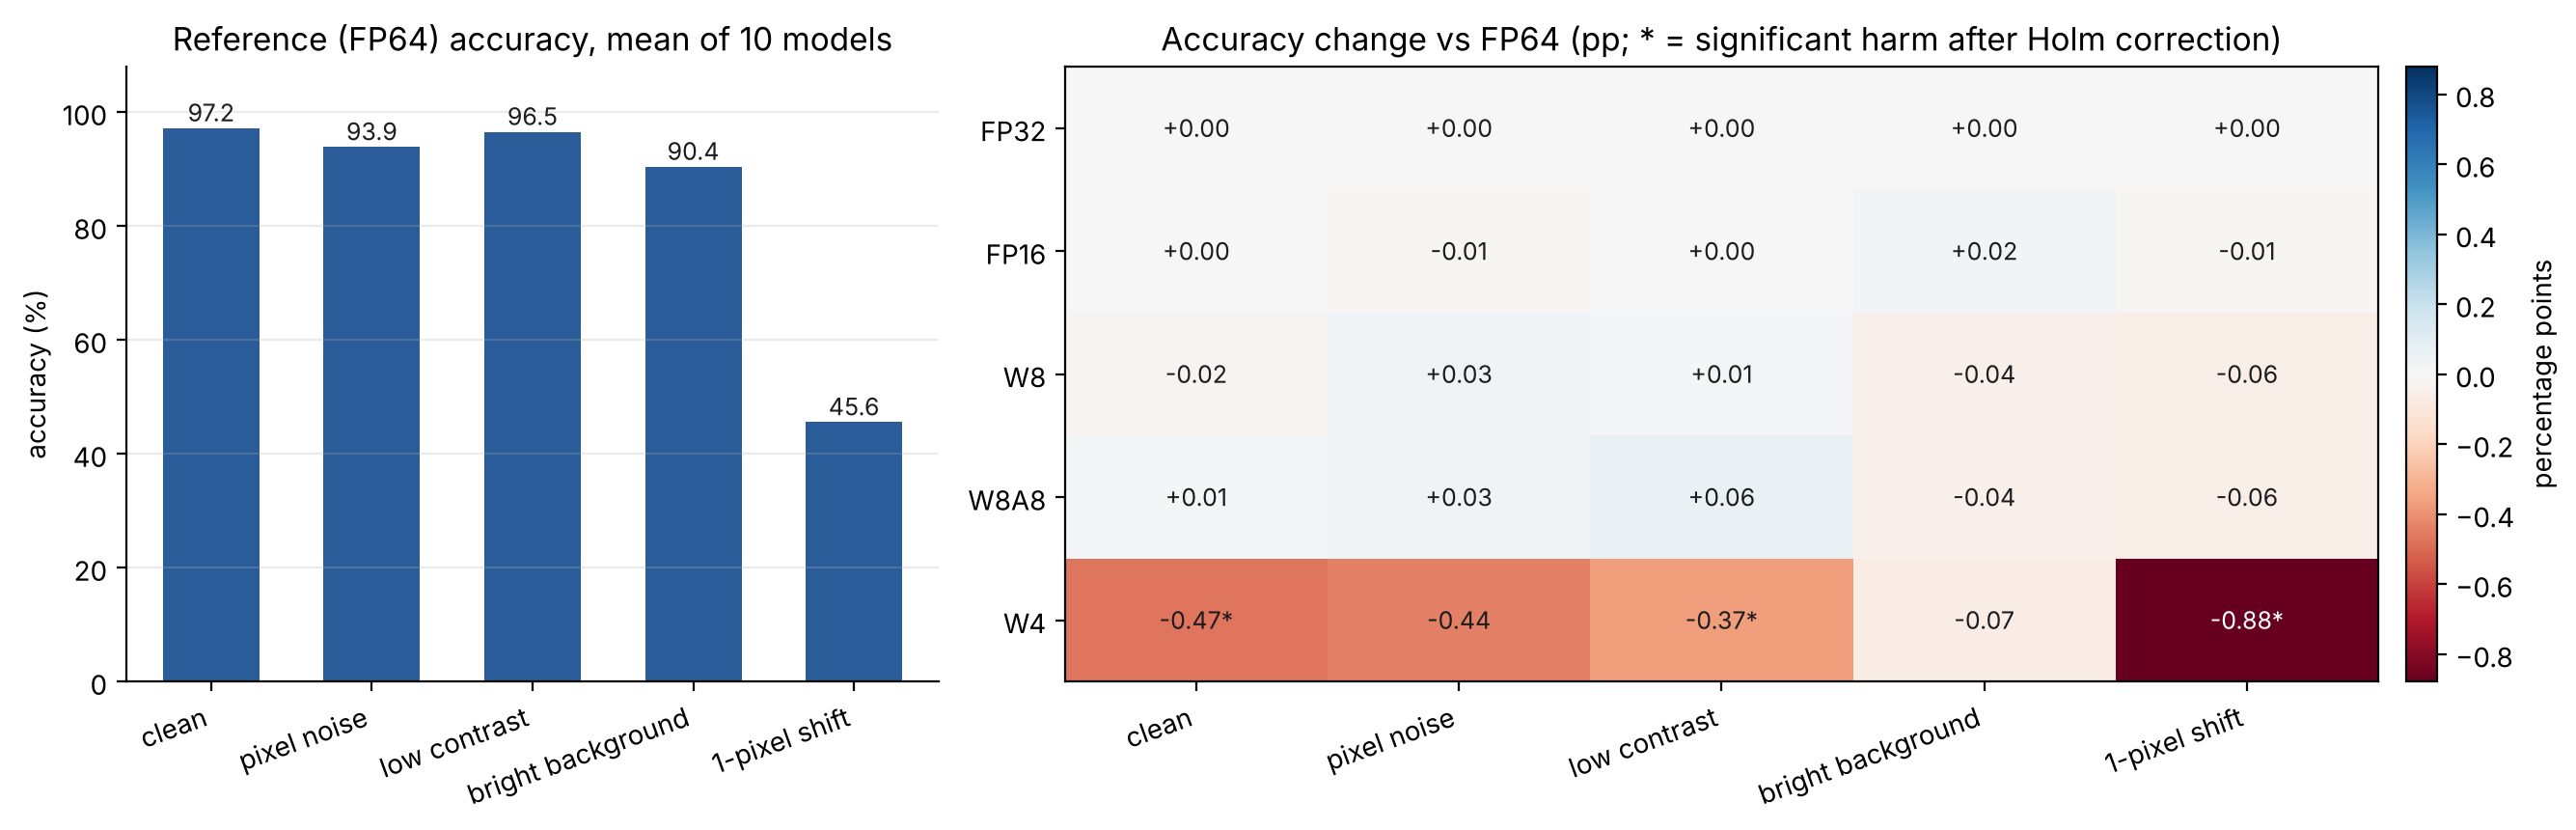

saved to config_drift_results/ | total run time 12.2 s


In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1, 1.7]})
ref = [100 * MC[("FP64", c)].mean() for c in CONDITIONS]
a1.bar(range(len(CONDITIONS)), ref, color="#2a5c9a", width=0.6)
for i, v in enumerate(ref):
    a1.text(i, v + 1.2, f"{v:.1f}", ha="center", fontsize=9, color="#1d1d1f")
a1.set_xticks(range(len(CONDITIONS)), list(CONDITIONS), rotation=20, ha="right")
a1.set_ylim(0, 108); a1.set_ylabel("accuracy (%)"); a1.set_title("Reference (FP64) accuracy, mean of 10 models")
a1.spines[["top", "right"]].set_visible(False); a1.grid(axis="y", alpha=0.25)

M = EFF.pivot(index="config", columns="condition", values="delta_pp").loc[CONFIGS[1:], list(CONDITIONS)]
S = EFF.pivot(index="config", columns="condition", values="significant_harm").loc[CONFIGS[1:], list(CONDITIONS)]
lim = max(0.5, float(np.abs(M.values).max()))
im = a2.imshow(M.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        a2.text(j, i, f"{v:+.2f}{'*' if S.values[i, j] else ''}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 * lim else "#1d1d1f")
a2.set_xticks(range(M.shape[1]), list(M.columns), rotation=20, ha="right")
a2.set_yticks(range(M.shape[0]), list(M.index))
a2.set_title("Accuracy change vs FP64 (pp; * = significant harm after Holm correction)")
fig.colorbar(im, ax=a2, fraction=0.03, pad=0.02, label="percentage points")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "config_drift_pilot.png"), dpi=200); plt.show()

for name, t in [("accuracy", ACC), ("config_effects", EFF), ("interaction", INT)]:
    t.to_csv(os.path.join(OUT, f"{name}.csv"), index=False)
with open(os.path.join(OUT, "environment.json"), "w") as f:
    json.dump(dict(ENV, seeds=SEEDS, hidden=list(HIDDEN), bootstrap=B, runtime_s=round(time.time() - T0, 1)), f, indent=1)
print("saved to", OUT + "/", f"| total run time {time.time() - T0:.1f} s")

## What this pilot shows, and what it does not

* It shows the protocol working end to end on a CPU: paired per-image comparisons, a measured run-to-run noise floor (zero here, because CPU inference is deterministic), exact tests with Holm correction, bootstrap intervals, and a configuration × shift interaction.
* Integer inference is simulated: weights and activations are rounded to the integer grid and converted back to floating point. The network is small, the dataset is tiny and the shifts are synthetic.
* It says nothing yet about LLM-based code tools. The GPU notebook (`LLM4SE_reliability_pilot.ipynb`) applies the same protocol to an open code model on HumanEval.